# Trabalho Prático — Computação Evolutiva (BCC461)
## Localização de facilidades com drones com energia mínima

**Aluno:** _preencher_

Este notebook implementa, com a biblioteca **DEAP**, um Algoritmo Genético para o problema de localização de bases de drones e compara os resultados com os valores de referência fornecidos pelo professor.

**Conteúdo**

1. Dados e visualização da instância
2. Modelagem do problema e função objetivo
3. Algoritmo Genético (DEAP)
4. Ajuste de parâmetros
5. Experimento final (P = 5, 10, 15, 20, 25, 30) e comparação com a referência
6. Extra (b): Algoritmo Memético (busca local)
7. Extra (a): versão capacitada
8. Extra (c): versão multiobjetivo (NSGA-II)
9. Conclusões

In [3]:
import random, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deap import base, creator, tools

# Pasta onde estão facility.csv, demand.csv e matriz_custos_cliente_facilidade.csv
DATA_DIR = "./dados"

# Estilo dos gráficos
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ad", "axes.titlesize": 11, "axes.labelsize": 10,
    "lines.linewidth": 2, "font.size": 10,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Dados e visualização da instância

- `facility.csv`: N = 104 locais candidatos para instalação das bases.
- `demand.csv`: M = 122 clientes, com a demanda (kg) de cada um.
- `matriz_custos_cliente_facilidade.csv`: matriz de consumo de energia. No arquivo ela tem **uma linha por cliente e uma coluna por facilidade** (122 × 104).

In [4]:
fac = pd.read_csv(f"{DATA_DIR}/facility.csv")
dem = pd.read_csv(f"{DATA_DIR}/demand.csv")
C = np.loadtxt(f"{DATA_DIR}/matriz_custos_cliente_facilidade.csv", delimiter=",")

M, N = C.shape                       # clientes, facilidades
peso = dem["Demand(kg)"].to_numpy()  # demanda de cada cliente
assert (M, N) == (len(dem), len(fac))
print(f"Clientes (M) = {M} | Facilidades candidatas (N) = {N}")
print(f"Consumo: min = {C.min():.0f}, mediana = {np.median(C):.0f}, max = {C.max():.0f}")
print(f"Demanda total = {peso.sum():.2f} kg")

Clientes (M) = 122 | Facilidades candidatas (N) = 104
Consumo: min = 2, mediana = 957, max = 4997
Demanda total = 366.50 kg


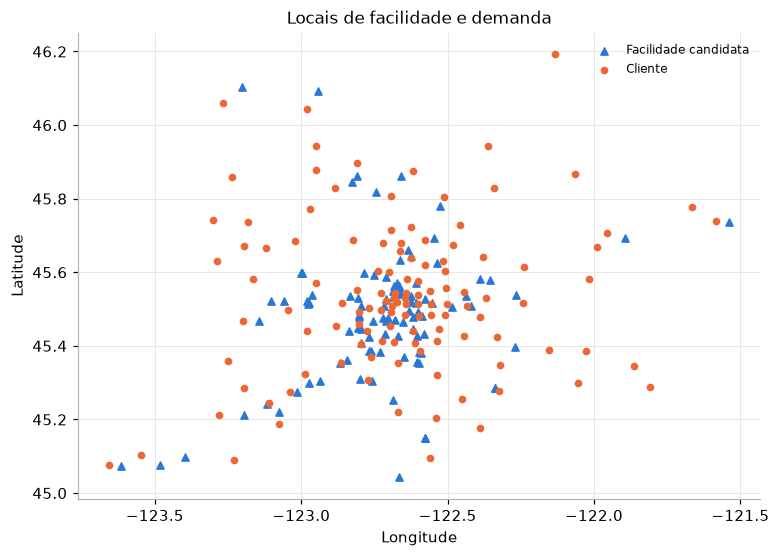

In [5]:
def desenhar_mapa(ax, abertas=None, atribuicao=None, titulo="Locais de facilidade e demanda"):
    # atribuicao[i] = índice da facilidade (0..N-1) que atende o cliente i, ou -1
    if atribuicao is not None:
        for i, j in enumerate(atribuicao):
            if j >= 0:
                ax.plot([dem.Longitude[i], fac.Longitude[j]], [dem.Latitude[i], fac.Latitude[j]],
                        color="#8a8982", lw=0.7, zorder=1)
    ax.scatter(fac.Longitude, fac.Latitude, marker="^", s=22, color="#9ec5f4" if abertas is not None else AZUL,
               label="Facilidade candidata", zorder=2)
    if abertas is not None:
        ax.scatter(fac.Longitude[abertas], fac.Latitude[abertas], marker="^", s=70, color=AZUL,
                   edgecolor="white", linewidth=0.8, label="Facilidade aberta", zorder=4)
    if atribuicao is not None:
        at = np.asarray(atribuicao) >= 0
        ax.scatter(dem.Longitude[at], dem.Latitude[at], s=16, color=LARANJA, label="Cliente atendido", zorder=3)
        ax.scatter(dem.Longitude[~at], dem.Latitude[~at], s=28, marker="x", color=CINZA,
                   label="Cliente não atendido", zorder=3)
    else:
        ax.scatter(dem.Longitude, dem.Latitude, s=16, color=LARANJA, label="Cliente", zorder=3)
    ax.set(xlabel="Longitude", ylabel="Latitude", title=titulo)
    ax.legend(loc="upper right", fontsize=8, frameon=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
desenhar_mapa(ax)
plt.show()

## 2. Modelagem do problema

**Decisão:** escolher exatamente **P** facilidades para abrir. Cada cliente é atendido pela facilidade aberta de menor consumo, desde que esse consumo não ultrapasse a autonomia **B** do drone. Clientes sem nenhuma facilidade aberta a até B ficam **sem atendimento**.

**Função objetivo (minimizar):**

$$f(S) = \sum_{i \,\in\, \text{atendidos}} \min_{j \in S} c_{ij} \;+\; \rho \cdot |\text{não atendidos}|$$

A penalidade ρ é necessária: sem ela, a melhor solução seria não atender ninguém (energia zero).

### Valores de B e ρ

O enunciado não informa os valores numéricos de **B** e da penalidade. Eles foram obtidos a partir das soluções de referência do professor:

- Para P = 5 a referência atende 98 clientes e tem fitness 276145. A soma de energia dos 98 atendidos é 36145, logo os 24 não atendidos contribuem com 240000, ou seja, **ρ = 10000 por cliente não atendido**. O mesmo vale para os demais valores de P.
- Pelos clientes atendidos / não atendidos da versão original, B está entre 609 e 621. A versão capacitada só é reproduzida com B ≥ 616. Adotou-se **B = 620**.

A célula abaixo confirma que, com esses dois valores, a função de avaliação reproduz **exatamente** os seis valores da tabela do professor (energia e número de clientes atendidos).

In [6]:
B   = 620      # autonomia do drone (inferida das soluções de referência)
PEN = 10_000   # penalidade por cliente não atendido (inferida das soluções de referência)

# Matriz penalizada: consumo acima de B vira PEN. Como PEN > B, basta tomar o mínimo por cliente.
Cp = np.where(C <= B, C, PEN)

def fitness_conjunto(S):
    # Energia total + penalidades para o conjunto de facilidades S
    return float(Cp[:, list(S)].min(axis=1).sum())

def detalhar(S):
    S = list(S)
    sub = Cp[:, S]
    menor = sub.min(axis=1)
    atend = menor < PEN
    atrib = np.where(atend, np.asarray(S)[sub.argmin(axis=1)], -1)
    return dict(fitness=float(menor.sum()), energia=float(menor[atend].sum()),
                atendidos=int(atend.sum()), atribuicao=atrib)

LISTA_P = [5, 10, 15, 20, 25, 30]

REF = {   # P: (energia ótima, facilidades, clientes atendidos) — versão original
    5:  (276145, [0, 18, 53, 66, 100], 98),
    10: (125903, [2, 10, 19, 21, 23, 26, 30, 54, 56, 82], 113),
    15: (88077,  [2, 4, 10, 11, 16, 18, 23, 26, 30, 34, 42, 43, 49, 56, 66], 116),
    20: (83630,  [2, 4, 5, 10, 11, 16, 18, 23, 26, 28, 30, 34, 35, 41, 42, 50, 56, 65, 66, 94], 116),
    25: (81532,  [1, 2, 4, 5, 10, 11, 16, 18, 23, 26, 27, 28, 30, 32, 34, 35, 41, 42, 52, 56, 65, 66, 72, 74, 97], 116),
    30: (80073,  [1, 2, 4, 5, 10, 11, 16, 17, 18, 19, 23, 24, 26, 27, 28, 30, 32, 34, 35, 41, 42, 56, 65, 66, 71, 72, 73, 74, 94, 97], 116),
}
OTIMO = {P: v[0] for P, v in REF.items()}

linhas = []
for P, (f_ref, S, at_ref) in REF.items():
    d = detalhar(S)
    linhas.append(dict(P=P, referencia=f_ref, calculado=d["fitness"], atendidos_ref=at_ref,
                       atendidos_calc=d["atendidos"], confere=(d["fitness"] == f_ref and d["atendidos"] == at_ref)))
verif = pd.DataFrame(linhas).set_index("P")
assert verif.confere.all()
print(f"Clientes que nenhuma facilidade alcança com B = {B}: {int((Cp.min(axis=1) >= PEN).sum())} "
      f"(máximo atendível = {int((Cp.min(axis=1) < PEN).sum())})")
verif

Clientes que nenhuma facilidade alcança com B = 620: 6 (máximo atendível = 116)


,referencia,calculado,atendidos_ref,atendidos_calc,confere
P,,,,,
5,276145,"276,145.00",98,98,True
10,125903,"125,903.00",113,113,True
15,88077,"88,077.00",116,116,True
20,83630,"83,630.00",116,116,True
25,81532,"81,532.00",116,116,True
30,80073,"80,073.00",116,116,True


## 3. Algoritmo Genético com DEAP

**Representação.** Um indivíduo é uma lista com **P índices distintos** de facilidades (um subconjunto de tamanho P). Assim a restrição "exatamente P facilidades" é satisfeita por construção, e nenhum operador precisa de reparo.

**Operadores.**

| Componente | Escolha |
|---|---|
| Inicialização | amostra aleatória de P facilidades distintas |
| Seleção de pais | torneio (tamanho 3) |
| Cruzamento | *cruzamento de conjuntos*: os filhos herdam as facilidades comuns aos dois pais; as demais (diferença simétrica) são embaralhadas e repartidas entre os filhos |
| Mutação | troca: cada facilidade aberta é substituída, com probabilidade 1/P, por uma facilidade fechada (pelo menos uma troca) |
| Sobrevivência | (μ + λ) elitista: os melhores entre pais e filhos, sem indivíduos repetidos |

O cruzamento de conjuntos preserva o que os pais têm em comum e só recombina o que os diferencia, mantendo o tamanho P. A eliminação de repetidos evita a convergência prematura, que nos testes iniciais prendia a população em ótimos locais (principalmente em P = 10).

In [7]:
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

def avaliar(ind):
    return (fitness_conjunto(ind),)

def cx_conjunto(a, b):
    # Mantém as facilidades comuns e redistribui as restantes entre os dois filhos
    sa, sb = set(a), set(b)
    comuns, dif = list(sa & sb), list(sa ^ sb)
    random.shuffle(dif)
    k = len(a) - len(comuns)
    a[:], b[:] = comuns + dif[:k], comuns + dif[k:]
    return a, b

def mut_troca(ind, indpb):
    # Troca facilidades abertas por facilidades fechadas (no mínimo uma troca)
    abertas = set(ind)
    fechadas = [j for j in range(N) if j not in abertas]
    random.shuffle(fechadas)
    trocou = False
    for pos in range(len(ind)):
        if random.random() < indpb:
            ind[pos] = fechadas.pop(); trocou = True
    if not trocou:
        ind[random.randrange(len(ind))] = fechadas.pop()
    return ind,

def criar_toolbox(P, avaliar_fn=avaliar, torneio=3):
    tb = base.Toolbox()
    tb.register("genes", random.sample, range(N), P)
    tb.register("individual", tools.initIterate, creator.Individual, tb.genes)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", avaliar_fn)
    tb.register("mate", cx_conjunto)
    tb.register("mutate", mut_troca, indpb=1.0 / P)
    tb.register("select", tools.selTournament, tournsize=torneio)
    return tb

In [8]:
def executar_ag(P, pop=100, cxpb=0.9, mutpb=0.4, ngen=150, seed=None,
                avaliar_fn=avaliar, busca_local=None, n_bl=0, torneio=3):
    # AG (mu + lambda) com DEAP. Se busca_local for informada, vira um Algoritmo Memético:
    # os n_bl melhores filhos de cada geração passam pela busca local.
    random.seed(seed)
    tb = criar_toolbox(P, avaliar_fn, torneio)
    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register("min", np.min); stats.register("media", np.mean)
    log = tools.Logbook(); log.header = ["gen", "nevals", "min", "media"]

    t0 = time.perf_counter()
    populacao = tb.population(n=pop)
    for ind in populacao:
        ind.fitness.values = tb.evaluate(ind)
    nevals = pop
    log.record(gen=0, nevals=nevals, **stats.compile(populacao))

    for gen in range(1, ngen + 1):
        filhos = [creator.Individual(ind) for ind in tb.select(populacao, pop)]
        for f1, f2 in zip(filhos[::2], filhos[1::2]):
            if random.random() < cxpb:
                tb.mate(f1, f2)
        for f in filhos:
            if random.random() < mutpb:
                tb.mutate(f)
        vistos = set()                       # filhos repetidos recebem mutação extra
        for f in filhos:
            chave = frozenset(f)
            while chave in vistos:
                tb.mutate(f); chave = frozenset(f)
            vistos.add(chave)
        for f in filhos:
            f.fitness.values = tb.evaluate(f)
        nevals += len(filhos)
        if busca_local is not None and n_bl > 0:
            for f in tools.selBest(filhos, n_bl):
                f.fitness.values = (busca_local(f),)
        unicos = {}
        for ind in populacao + filhos:       # sobrevivência (mu + lambda) sem repetidos
            unicos.setdefault(frozenset(ind), ind)
        populacao = tools.selBest(list(unicos.values()), pop)
        log.record(gen=gen, nevals=nevals, **stats.compile(populacao))

    melhor = populacao[0]
    return dict(P=P, seed=seed, fitness=melhor.fitness.values[0], solucao=sorted(melhor),
                tempo=time.perf_counter() - t0, nevals=nevals, log=log, populacao=populacao)

# Teste rápido
r = executar_ag(10, seed=1)
print(f"P=10 | fitness = {r['fitness']:.0f} (ótimo {OTIMO[10]}) | {r['nevals']} avaliações | {r['tempo']:.2f} s")
print("Facilidades:", r["solucao"])

P=10 | fitness = 126283 (ótimo 125903) | 15100 avaliações | 0.93 s
Facilidades: [2, 10, 16, 18, 23, 26, 30, 42, 56, 90]


## 4. Ajuste de parâmetros

Foram combinados **três parâmetros** em uma grade completa:

- tamanho da população: 50, 100, 200
- probabilidade de mutação: 0.2, 0.4, 0.6
- probabilidade de cruzamento: 0.7, 0.9

Para a comparação ser justa, todas as configurações usam o **mesmo orçamento de 15 000 avaliações** da função objetivo (o número de gerações é ajustado conforme a população). Cada configuração é executada 5 vezes em P = 10, 20 e 30, e a medida de qualidade é o **gap médio** em relação ao ótimo: `gap = 100 · (fitness − ótimo) / ótimo`.

In [9]:
ORCAMENTO_AJUSTE = 15_000
GRADE = dict(pop=[50, 100, 200], mutpb=[0.2, 0.4, 0.6], cxpb=[0.7, 0.9])
P_AJUSTE, SEEDS_AJUSTE = [10, 20, 30], range(5)

def gap(f, P, otimo=OTIMO):
    return 100.0 * (f - otimo[P]) / otimo[P]

t0 = time.perf_counter()
reg = []
for pop, mutpb, cxpb in itertools.product(GRADE["pop"], GRADE["mutpb"], GRADE["cxpb"]):
    ngen = ORCAMENTO_AJUSTE // pop - 1
    for P in P_AJUSTE:
        for s in SEEDS_AJUSTE:
            r = executar_ag(P, pop=pop, cxpb=cxpb, mutpb=mutpb, ngen=ngen, seed=s)
            reg.append(dict(pop=pop, mutpb=mutpb, cxpb=cxpb, P=P, seed=s,
                            gap=gap(r["fitness"], P), otimo=r["fitness"] == OTIMO[P]))
ajuste = pd.DataFrame(reg)
print(f"{len(ajuste)} execuções em {time.perf_counter() - t0:.0f} s")

resumo_ajuste = (ajuste.groupby(["pop", "mutpb", "cxpb"])
                 .agg(gap_medio=("gap", "mean"), gap_dp=("gap", "std"), gap_max=("gap", "max"),
                      otimos=("otimo", "sum"))
                 .sort_values(["gap_medio", "gap_dp"]).reset_index())
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
resumo_ajuste

270 execuções em 186 s


,pop,mutpb,cxpb,gap_medio,gap_dp,gap_max,otimos
0,200,0.400,0.900,0.163,0.133,0.430,0
1,100,0.400,0.700,0.174,0.191,0.568,2
2,100,0.200,0.700,0.174,0.122,0.304,1
3,200,0.600,0.900,0.212,0.143,0.524,0
4,200,0.200,0.700,0.216,0.183,0.641,0
5,200,0.600,0.700,0.280,0.190,0.698,0
6,200,0.400,0.700,0.293,0.208,0.740,0
7,50,0.600,0.900,0.598,1.907,7.477,3
8,100,0.400,0.900,0.611,1.903,7.477,2
9,100,0.600,0.700,0.652,1.944,7.656,2


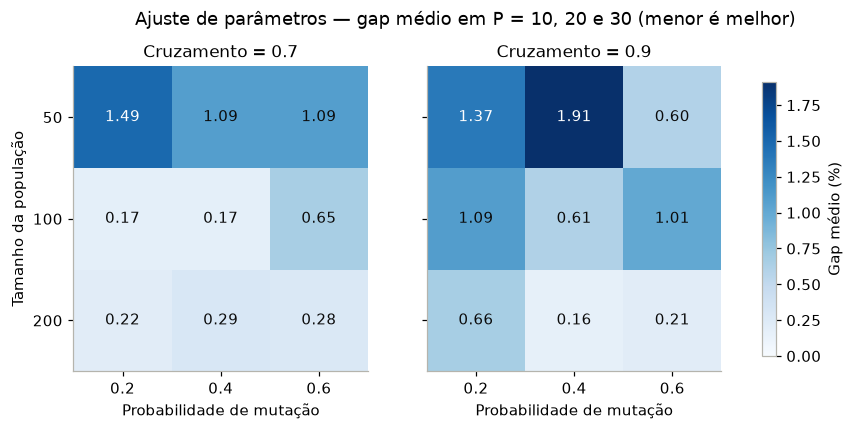

Configuração escolhida: {'pop': 200, 'mutpb': 0.4, 'cxpb': 0.9} | gap médio = 0.163%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
vmax = resumo_ajuste.gap_medio.max()
for ax, cxpb in zip(axes, GRADE["cxpb"]):
    tab = (resumo_ajuste[resumo_ajuste.cxpb == cxpb]
           .pivot(index="pop", columns="mutpb", values="gap_medio"))
    im = ax.imshow(tab.values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(tab.columns)), tab.columns); ax.set_yticks(range(len(tab.index)), tab.index)
    ax.set(xlabel="Probabilidade de mutação", title=f"Cruzamento = {cxpb}"); ax.grid(False)
    for (i, j), v in np.ndenumerate(tab.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 * vmax else "#0b0b0b")
axes[0].set_ylabel("Tamanho da população")
fig.colorbar(im, ax=axes, label="Gap médio (%)", shrink=0.9)
fig.suptitle("Ajuste de parâmetros — gap médio em P = 10, 20 e 30 (menor é melhor)", y=1.02)
plt.show()

melhor_cfg = resumo_ajuste.iloc[0]
CFG = dict(pop=int(melhor_cfg["pop"]), mutpb=float(melhor_cfg["mutpb"]), cxpb=float(melhor_cfg["cxpb"]))
print("Configuração escolhida:", CFG, f"| gap médio = {melhor_cfg.gap_medio:.3f}%")

## 5. Experimento final

O algoritmo final usa a configuração escolhida acima, agora com orçamento de **30 000 avaliações** por execução. São feitas **20 execuções independentes** (sementes diferentes das usadas no ajuste) para cada P ∈ {5, 10, 15, 20, 25, 30}.

In [11]:
ORCAMENTO_FINAL, N_EXEC = 30_000, 20
SEEDS_FINAL = range(100, 100 + N_EXEC)

def rodar_experimento(seeds, otimo=OTIMO, **kw):
    execs = []
    for P in LISTA_P:
        for s in seeds:
            r = executar_ag(P, seed=s, **kw)
            r["gap"] = gap(r["fitness"], P, otimo)
            execs.append(r)
    return execs

def tabela_resumo(execs, otimo=OTIMO):
    df = pd.DataFrame([{k: r[k] for k in ("P", "fitness", "gap", "tempo")} for r in execs])
    g = df.groupby("P")
    tab = pd.DataFrame({
        "referência": pd.Series(otimo),
        "melhor": g.fitness.min(), "média": g.fitness.mean(), "desvio": g.fitness.std(), "pior": g.fitness.max(),
        "gap melhor (%)": g.gap.min(), "gap médio (%)": g.gap.mean(),
        "nº ótimos": g.apply(lambda d: int((d.fitness <= otimo[d.name] + 1e-6).sum())),
        "tempo médio (s)": g.tempo.mean(),
    })
    tab.index.name = "P"
    return tab

t0 = time.perf_counter()
exec_ag = rodar_experimento(SEEDS_FINAL, ngen=ORCAMENTO_FINAL // CFG["pop"] - 1, **CFG)
print(f"{len(exec_ag)} execuções em {time.perf_counter() - t0:.0f} s")
tab_ag = tabela_resumo(exec_ag)
tab_ag.style.format({"referência": "{:.0f}", "melhor": "{:.0f}", "média": "{:.1f}", "desvio": "{:.1f}",
                     "pior": "{:.0f}", "gap melhor (%)": "{:.3f}", "gap médio (%)": "{:.3f}",
                     "tempo médio (s)": "{:.2f}"})

120 execuções em 159 s


,referência,melhor,média,desvio,pior,gap melhor (%),gap médio (%),nº ótimos,tempo médio (s)
P,,,,,,,,,
5,276145,276145,276153.4,37.6,276313,0.000,0.003,19,1.16
10,125903,125903,126715.7,2026.3,135317,0.000,0.645,1,1.19
15,88077,88077,88129.2,121.3,88533,0.000,0.059,13,1.26
20,83630,83630,83664.1,56.0,83799,0.000,0.041,9,1.38
25,81532,81532,81550.8,20.3,81625,0.000,0.023,4,1.49
30,80073,80073,80107.1,43.0,80205,0.000,0.043,6,1.48


In [12]:
def melhor_por_P(execs):
    out = {}
    for r in execs:
        if r["P"] not in out or r["fitness"] < out[r["P"]]["fitness"]:
            out[r["P"]] = r
    return out

melhores_ag = melhor_por_P(exec_ag)
linhas = []
for P in LISTA_P:
    d = detalhar(melhores_ag[P]["solucao"])
    assert len(set(melhores_ag[P]["solucao"])) == P            # exatamente P facilidades
    linhas.append(dict(P=P, energia_ref=OTIMO[P], energia_AG=d["fitness"], atendidos_ref=REF[P][2],
                       atendidos_AG=d["atendidos"], facilidades_AG=melhores_ag[P]["solucao"]))
pd.set_option("display.max_colwidth", None)
pd.DataFrame(linhas).set_index("P").style.format({"energia_AG": "{:.0f}"})

,energia_ref,energia_AG,atendidos_ref,atendidos_AG,facilidades_AG
P,,,,,
5,276145,276145,98,98,"[0, 18, 53, 66, 100]"
10,125903,125903,113,113,"[2, 10, 19, 21, 23, 26, 30, 54, 56, 82]"
15,88077,88077,116,116,"[2, 4, 10, 11, 16, 18, 23, 26, 30, 34, 42, 43, 49, 56, 66]"
20,83630,83630,116,116,"[2, 4, 5, 10, 11, 16, 18, 23, 26, 34, 35, 41, 42, 50, 56, 64, 65, 66, 81, 94]"
25,81532,81532,116,116,"[1, 2, 4, 5, 10, 11, 16, 18, 23, 26, 27, 30, 32, 34, 35, 41, 42, 52, 56, 64, 65, 66, 72, 74, 97]"
30,80073,80073,116,116,"[1, 2, 4, 5, 10, 11, 16, 17, 18, 19, 23, 24, 26, 27, 32, 34, 35, 41, 42, 56, 64, 65, 66, 71, 72, 73, 74, 81, 94, 97]"


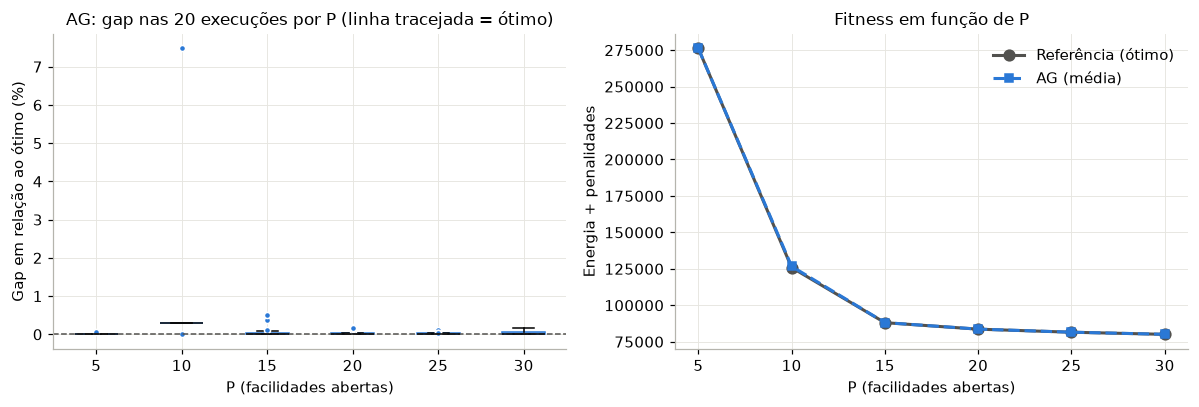

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (a) distribuição do gap nas 20 execuções
ax = axes[0]
dados = [[r["gap"] for r in exec_ag if r["P"] == P] for P in LISTA_P]
bp = ax.boxplot(dados, tick_labels=[str(P) for P in LISTA_P], patch_artist=True, widths=0.5,
                medianprops=dict(color="#0b0b0b"), flierprops=dict(marker="o", markersize=4, markerfacecolor=AZUL, markeredgecolor="white"))
for b in bp["boxes"]:
    b.set(facecolor="#9ec5f4", edgecolor=AZUL)
ax.axhline(0, color=CINZA, lw=1, ls="--")
ax.set(xlabel="P (facilidades abertas)", ylabel="Gap em relação ao ótimo (%)",
       title=f"AG: gap nas {N_EXEC} execuções por P (linha tracejada = ótimo)")

# (b) melhor resultado x referência
ax = axes[1]
ax.plot(LISTA_P, [OTIMO[P] for P in LISTA_P], color=CINZA, marker="o", ms=7, label="Referência (ótimo)")
ax.plot(LISTA_P, tab_ag["média"], color=AZUL, marker="s", ms=5, ls="--", label="AG (média)")
ax.set(xlabel="P (facilidades abertas)", ylabel="Energia + penalidades", title="Fitness em função de P", xticks=LISTA_P)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

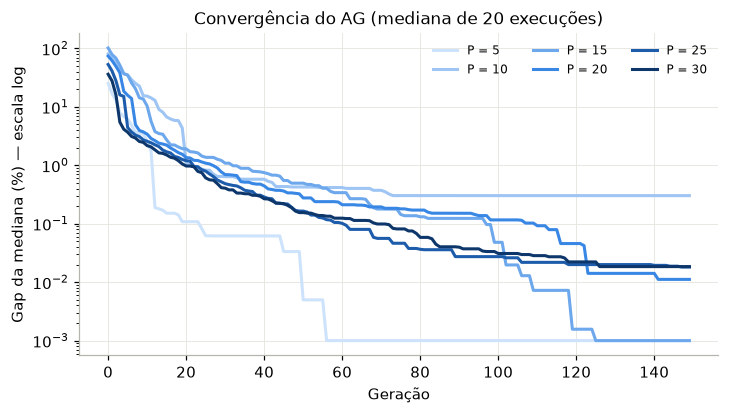

In [14]:
# Convergência: mediana do melhor fitness por geração (relativo ao ótimo)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
cores = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
for P, cor in zip(LISTA_P, cores):
    curvas = np.array([r["log"].select("min") for r in exec_ag if r["P"] == P])
    med = np.median(curvas, axis=0)
    ax.plot(100 * (med - OTIMO[P]) / OTIMO[P] + 1e-3, color=cor, label=f"P = {P}")
ax.set(yscale="log", xlabel="Geração", ylabel="Gap da mediana (%) — escala log",
       title="Convergência do AG (mediana de 20 execuções)")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

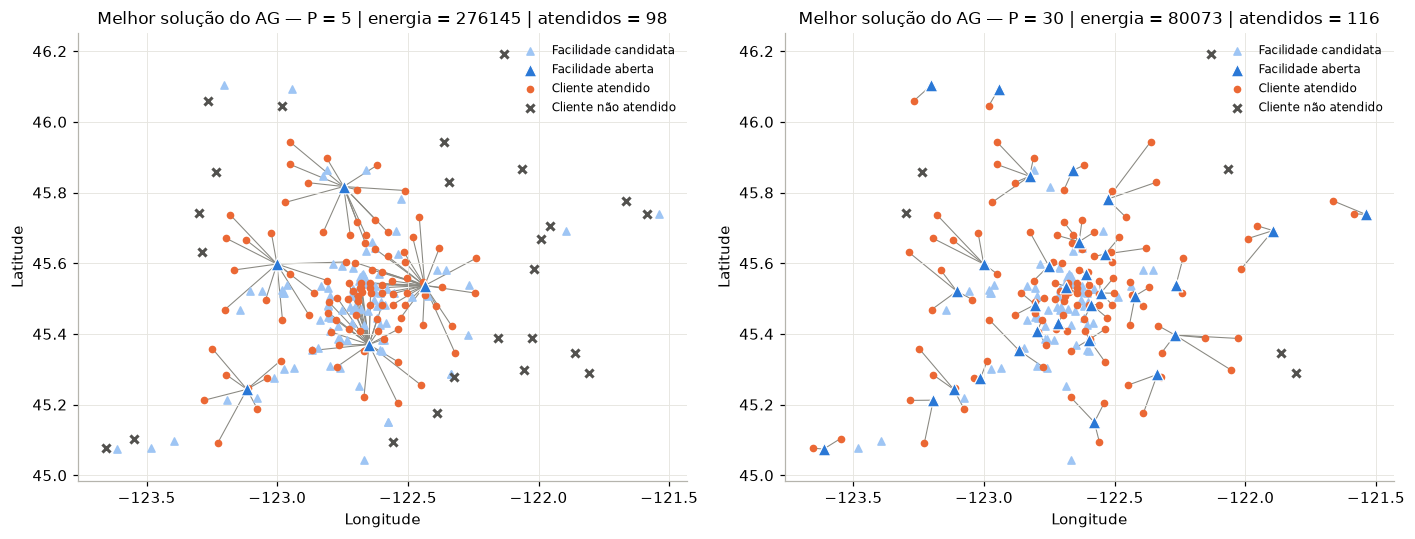

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, P in zip(axes, (5, 30)):
    d = detalhar(melhores_ag[P]["solucao"])
    desenhar_mapa(ax, abertas=melhores_ag[P]["solucao"], atribuicao=d["atribuicao"],
                  titulo=f"Melhor solução do AG — P = {P} | energia = {d['fitness']:.0f} | atendidos = {d['atendidos']}")
plt.tight_layout(); plt.show()

## 6. Extra (b): Algoritmo Memético

O AG é combinado com uma **busca local de troca (swap)**: para a solução atual, avalia-se a troca de cada facilidade aberta por cada facilidade fechada, aplica-se a melhor troca e repete-se até não haver melhora (ótimo local). A vizinhança inteira é avaliada de forma vetorizada com NumPy, usando o menor e o segundo menor consumo de cada cliente.

A cada geração, os **2 melhores filhos** passam pela busca local e voltam para a população já melhorados (aprendizado lamarckiano). Como a busca local faz o trabalho de intensificação, o memético usa população e número de gerações bem menores.

In [16]:
def busca_local_troca(ind, max_iter=100):
    # Melhor troca aberta <-> fechada até atingir um ótimo local. Altera ind e devolve o fitness.
    S = list(ind)
    f = fitness_conjunto(S)
    linhas_idx = np.arange(M)
    for _ in range(max_iter):
        sub = Cp[:, S]
        abertas = set(S)
        fechadas = np.array([j for j in range(N) if j not in abertas])
        ordem = np.argsort(sub, axis=1)[:, :2]
        d1, d2 = sub[linhas_idx, ordem[:, 0]], sub[linhas_idx, ordem[:, 1]]
        melhor = (f, None, None)
        for pos in range(len(S)):
            # consumo de cada cliente se a facilidade da posição pos for fechada
            sem = np.where(ordem[:, 0] == pos, d2, d1)
            totais = np.minimum(sem[:, None], Cp[:, fechadas]).sum(axis=0)
            k = int(totais.argmin())
            if totais[k] < melhor[0] - 1e-9:
                melhor = (float(totais[k]), pos, int(fechadas[k]))
        if melhor[1] is None:
            break
        f, S[melhor[1]] = melhor[0], melhor[2]
    ind[:] = S
    return f

CFG_AM = dict(pop=60, ngen=100, cxpb=CFG["cxpb"], mutpb=CFG["mutpb"], busca_local=busca_local_troca, n_bl=2)

t0 = time.perf_counter()
exec_am = rodar_experimento(SEEDS_FINAL, **CFG_AM)
print(f"{len(exec_am)} execuções em {time.perf_counter() - t0:.0f} s")
tab_am = tabela_resumo(exec_am)
tab_am.style.format({"referência": "{:.0f}", "melhor": "{:.0f}", "média": "{:.1f}", "desvio": "{:.1f}",
                     "pior": "{:.0f}", "gap melhor (%)": "{:.3f}", "gap médio (%)": "{:.3f}",
                     "tempo médio (s)": "{:.2f}"})

120 execuções em 61 s


,referência,melhor,média,desvio,pior,gap melhor (%),gap médio (%),nº ótimos,tempo médio (s)
P,,,,,,,,,
5,276145,276145,276153.4,37.6,276313,0.000,0.003,19,0.35
10,125903,125903,127110.4,2810.8,135317,0.000,0.959,4,0.45
15,88077,88077,88077.0,0.0,88077,0.000,0.000,20,0.54
20,83630,83630,83630.0,0.0,83630,0.000,0.000,20,0.54
25,81532,81532,81537.9,6.6,81545,0.000,0.007,11,0.58
30,80073,80073,80077.2,8.9,80100,0.000,0.005,16,0.62


,referência,AG gap médio (%),AM gap médio (%),AG nº ótimos,AM nº ótimos,AG tempo (s),AM tempo (s)
P,,,,,,,
5,276145,0.003,0.003,19,19,1.16,0.35
10,125903,0.645,0.959,1,4,1.19,0.45
15,88077,0.059,0.000,13,20,1.26,0.54
20,83630,0.041,0.000,9,20,1.38,0.54
25,81532,0.023,0.007,4,11,1.49,0.58
30,80073,0.043,0.005,6,16,1.48,0.62


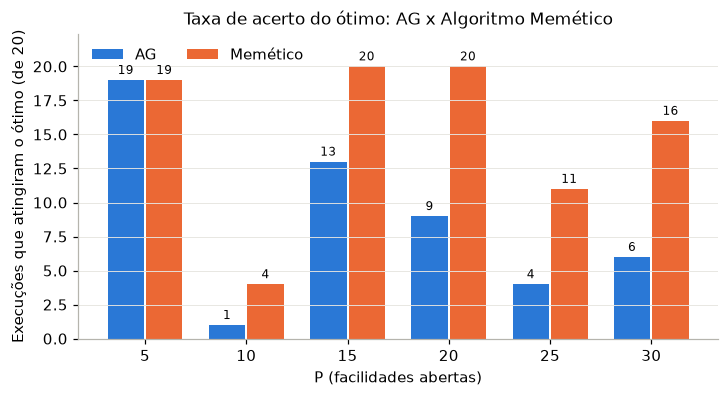

In [17]:
comp = pd.DataFrame({
    "referência": pd.Series(OTIMO),
    "AG gap médio (%)": tab_ag["gap médio (%)"], "AM gap médio (%)": tab_am["gap médio (%)"],
    "AG nº ótimos": tab_ag["nº ótimos"], "AM nº ótimos": tab_am["nº ótimos"],
    "AG tempo (s)": tab_ag["tempo médio (s)"], "AM tempo (s)": tab_am["tempo médio (s)"],
})
comp.index.name = "P"
display(comp.style.format({"referência": "{:.0f}", "AG gap médio (%)": "{:.3f}", "AM gap médio (%)": "{:.3f}",
                           "AG tempo (s)": "{:.2f}", "AM tempo (s)": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(LISTA_P)); larg = 0.36
b1 = ax.bar(x - larg / 2 - 0.01, tab_ag["nº ótimos"], larg, color=AZUL, label="AG")
b2 = ax.bar(x + larg / 2 + 0.01, tab_am["nº ótimos"], larg, color=LARANJA, label="Memético")
ax.bar_label(b1, padding=2, fontsize=8); ax.bar_label(b2, padding=2, fontsize=8)
ax.set(xticks=x, xticklabels=LISTA_P, xlabel="P (facilidades abertas)", ylabel=f"Execuções que atingiram o ótimo (de {N_EXEC})",
       title="Taxa de acerto do ótimo: AG x Algoritmo Memético", ylim=(0, N_EXEC * 1.12))
ax.grid(axis="x", visible=False); ax.legend(frameon=False, ncol=2, loc="upper left")
plt.show()

## 7. Extra (a): versão capacitada

Cada facilidade aberta atende no máximo **U** kg de demanda (soma dos `peso_i` dos clientes atribuídos a ela). Agora um cliente pode precisar ser atendido por uma facilidade que não é a mais próxima, ou ficar sem atendimento por falta de capacidade.

### Valor de U

O enunciado também não traz o valor de U. Testando as soluções capacitadas de referência com um modelo exato de atribuição, o único valor que reproduz as seis energias da tabela é

$$U = 1{,}25 \cdot \frac{\sum_i peso_i}{P}$$

ou seja, a capacidade total instalada é 125% da demanda total, dividida igualmente entre as P facilidades (U diminui quando P aumenta). A verificação está na célula abaixo.

### Decodificação

O cromossomo continua sendo o conjunto de P facilidades. Dado o conjunto, a atribuição cliente → facilidade é um problema de atribuição generalizada (NP-difícil), resolvido aqui por uma **heurística construtiva com reparo**:

1. ordena os clientes pelo número de facilidades abertas que os alcançam (menos opções primeiro) e, em caso de empate, pelo menor consumo;
2. atribui cada cliente à facilidade mais próxima com capacidade livre;
3. **reparo**: para cada cliente que sobrou, tenta abrir espaço deslocando clientes já atribuídos para outras facilidades (cadeia de ejeção de até 2 níveis);
4. **melhoria**: realoca clientes para facilidades mais próximas, diretamente ou trocando de lugar com outro cliente.

Para conferência, a função `atribuicao_exata` resolve a mesma atribuição de forma ótima com programação inteira (`scipy.optimize.milp`). Ela **não** é usada dentro do AG, apenas para verificar a referência e medir quanto a heurística perde.

In [18]:
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix

TOTAL_DEMANDA = float(peso.sum())
def capacidade(P):
    return 1.25 * TOTAL_DEMANDA / P

REF_CAP = {   # P: (energia ótima, facilidades) — versão capacitada
    5:  (276267, [0, 13, 18, 53, 100]),
    10: (146632, [2, 10, 16, 18, 26, 34, 43, 56, 59, 60]),
    15: (93840,  [0, 2, 10, 11, 19, 21, 23, 30, 31, 43, 54, 56, 60, 92, 99]),
    20: (84818,  [2, 4, 5, 10, 11, 12, 13, 16, 17, 23, 26, 30, 34, 35, 41, 56, 65, 72, 84, 94]),
    25: (82119,  [2, 4, 5, 10, 11, 16, 17, 19, 23, 26, 27, 34, 35, 41, 42, 50, 56, 60, 64, 65, 74, 77, 80, 81, 94]),
    30: (80477,  [1, 2, 3, 4, 5, 10, 11, 16, 17, 18, 23, 26, 27, 28, 30, 32, 34, 35, 41, 42, 52, 56, 65, 66, 72, 74, 80, 82, 94, 97]),
}
OTIMO_CAP = {P: v[0] for P, v in REF_CAP.items()}

def atribuicao_exata(S, limite_tempo=60):
    # Atribuição ótima cliente -> facilidade para um conjunto S fixo (programação inteira)
    S = list(S); P = len(S); U = capacidade(P); sub = Cp[:, S]
    pares = [(i, j) for i in range(M) for j in range(P) if sub[i, j] < PEN]
    custo = np.array([sub[i, j] - PEN for i, j in pares])      # atender economiza a penalidade
    A = lil_matrix((M + P, len(pares)))
    for k, (i, j) in enumerate(pares):
        A[i, k] = 1            # cada cliente em no máximo uma facilidade
        A[M + j, k] = peso[i]  # capacidade da facilidade
    res = milp(custo, constraints=LinearConstraint(A.tocsr(), -np.inf, np.r_[np.ones(M), np.full(P, U)]),
               integrality=np.ones(len(pares)), bounds=Bounds(0, 1), options={"time_limit": limite_tempo})
    return float(round(res.fun + PEN * M)), int(round(res.x.sum()))

linhas = []
for P, (f_ref, S) in REF_CAP.items():
    f, atend = atribuicao_exata(S)
    linhas.append(dict(P=P, U=capacidade(P), referencia=f_ref, calculado=f, atendidos=atend, confere=(f == f_ref)))
verif_cap = pd.DataFrame(linhas).set_index("P")
assert verif_cap.confere.all()
verif_cap.style.format({"U": "{:.2f}", "calculado": "{:.0f}"})

,U,referencia,calculado,atendidos,confere
P,,,,,
5,91.62,276267,276267,98,True
10,45.81,146632,146632,111,True
15,30.54,93840,93840,116,True
20,22.91,84818,84818,116,True
25,18.32,82119,82119,116,True
30,15.27,80477,80477,116,True


In [19]:
pesos_l = peso.tolist()
EPS = 1e-9

def decodificar_capacitado(ind, profundidade=2):
    # Heurística de atribuição com capacidade. Devolve (fitness, atribuicao), com atribuicao[i] = posição em ind ou -1.
    P = len(ind); U = capacidade(P)
    sub = Cp[:, ind]
    pref = np.argsort(sub, axis=1, kind="stable")
    ordenado = np.take_along_axis(sub, pref, axis=1)
    n_viaveis = (ordenado < PEN).sum(axis=1)
    ordem = np.lexsort((ordenado[:, 0], n_viaveis))             # menos opções primeiro
    custo = sub.tolist()
    prefs = [p[:n] for p, n in zip(pref.tolist(), n_viaveis.tolist())]
    carga = [0.0] * P; atrib = [-1] * M; membros = [[] for _ in range(P)]

    def mover(i, j):
        atual = atrib[i]
        if atual >= 0:
            membros[atual].remove(i); carga[atual] -= pesos_l[i]
        membros[j].append(i); carga[j] += pesos_l[i]; atrib[i] = j

    bloqueadas = set()
    def inserir(i, j, nivel, fixos):
        # coloca i em j; se não couber, expulsa um cliente de j para outra facilidade
        wi = pesos_l[i]
        if carga[j] + wi <= U + EPS:
            mover(i, j); return True
        if nivel == 0:
            return False
        falta = carga[j] + wi - U
        candidatos = sorted((k for k in membros[j] if pesos_l[k] + EPS >= falta and k not in fixos),
                            key=lambda k: pesos_l[k])
        for k in candidatos:
            for j2 in prefs[k]:
                if j2 != j and j2 not in bloqueadas and carga[j2] + pesos_l[k] <= U + EPS:
                    mover(k, j2); mover(i, j); return True
            if nivel > 1:
                for j2 in prefs[k]:
                    if j2 != j and j2 not in bloqueadas:
                        bloqueadas.add(j)
                        membros[j].remove(k); carga[j] -= pesos_l[k]; atrib[k] = -1
                        ok = inserir(k, j2, nivel - 1, fixos | {i, k})
                        bloqueadas.discard(j)
                        if ok:
                            mover(i, j); return True
                        membros[j].append(k); carga[j] += pesos_l[k]; atrib[k] = j
        return False

    pendentes = []
    for i in ordem.tolist():                                    # construção gulosa
        for j in prefs[i]:
            if carga[j] + pesos_l[i] <= U + EPS:
                mover(i, j); break
        else:
            if prefs[i]:
                pendentes.append(i)
    for i in pendentes:                                         # reparo
        for j in prefs[i]:
            bloqueadas.clear()
            if inserir(i, j, profundidade, {i}):
                break
    for _ in range(3):                                          # melhoria
        mudou = False
        for i in range(M):
            j = atrib[i]
            if j < 0:
                continue
            ci, wi = custo[i], pesos_l[i]
            for j2 in prefs[i]:
                if j2 == j:
                    break                                       # só interessa facilidade melhor que a atual
                if carga[j2] + wi <= U + EPS:
                    mover(i, j2); mudou = True; break
                ganho_i, melhor = ci[j] - ci[j2], None
                for k in membros[j2]:
                    ck, wk = custo[k], pesos_l[k]
                    if ck[j] < PEN and carga[j2] - wk + wi <= U + EPS and carga[j] - wi + wk <= U + EPS:
                        ganho = ganho_i - (ck[j] - ck[j2])
                        if ganho > EPS and (melhor is None or ganho > melhor[0]):
                            melhor = (ganho, k)
                if melhor:
                    k = melhor[1]
                    atrib[i] = -1; membros[j].remove(i); carga[j] -= wi
                    mover(k, j); mover(i, j2); mudou = True; break
        if not mudou:
            break
    assert max(carga) <= U + 1e-6
    total = sum(custo[i][atrib[i]] if atrib[i] >= 0 else PEN for i in range(M))
    return float(total), atrib

CACHE_CAP = {}
def avaliar_capacitado(ind):
    chave = frozenset(ind)
    if chave not in CACHE_CAP:
        CACHE_CAP[chave] = decodificar_capacitado(sorted(ind))[0]
    return (CACHE_CAP[chave],)

# Qualidade da heurística nas soluções de referência (onde o valor ótimo é conhecido)
pd.DataFrame([dict(P=P, otimo=f, heuristica=decodificar_capacitado(S)[0],
                   perda_pct=100 * (decodificar_capacitado(S)[0] - f) / f) for P, (f, S) in REF_CAP.items()]
             ).set_index("P").style.format({"heuristica": "{:.0f}", "perda_pct": "{:.2f}"})

,otimo,heuristica,perda_pct
P,,,
5,276267,276278,0.00
10,146632,146859,0.15
15,93840,95069,1.31
20,84818,85725,1.07
25,82119,83260,1.39
30,80477,80557,0.10


In [ ]:
N_EXEC_CAP = 10
t0 = time.perf_counter()
exec_cap = []
for P in LISTA_P:
    for s in range(200, 200 + N_EXEC_CAP):
        CACHE_CAP.clear()
        r = executar_ag(P, seed=s, avaliar_fn=avaliar_capacitado, pop=100, ngen=150, cxpb=CFG["cxpb"], mutpb=CFG["mutpb"])
        r["gap"] = gap(r["fitness"], P, OTIMO_CAP)
        exec_cap.append(r)
print(f"{len(exec_cap)} execuções em {time.perf_counter() - t0:.0f} s")

tab_cap = tabela_resumo(exec_cap, OTIMO_CAP)
# Para a melhor solução de cada P: valor com a atribuição ótima (mesmo conjunto de facilidades)
melhores_cap = melhor_por_P(exec_cap)
exato = {P: atribuicao_exata(melhores_cap[P]["solucao"]) for P in LISTA_P}
tab_cap["melhor c/ atribuição exata"] = pd.Series({P: v[0] for P, v in exato.items()})
tab_cap["gap c/ atribuição exata (%)"] = [gap(exato[P][0], P, OTIMO_CAP) for P in LISTA_P]
tab_cap["atendidos"] = pd.Series({P: v[1] for P, v in exato.items()})
tab_cap.style.format({"referência": "{:.0f}", "melhor": "{:.0f}", "média": "{:.1f}", "desvio": "{:.1f}", "pior": "{:.0f}",
                      "gap melhor (%)": "{:.3f}", "gap médio (%)": "{:.3f}", "tempo médio (s)": "{:.2f}",
                      "melhor c/ atribuição exata": "{:.0f}", "gap c/ atribuição exata (%)": "{:.3f}"})

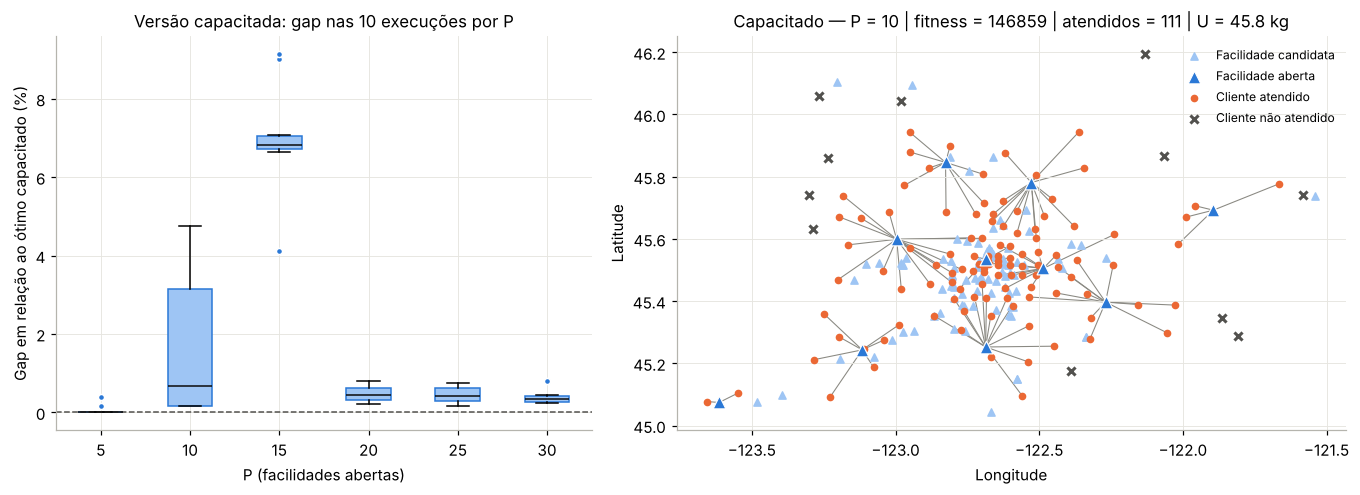

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axes[0]
dados = [[r["gap"] for r in exec_cap if r["P"] == P] for P in LISTA_P]
bp = ax.boxplot(dados, tick_labels=[str(P) for P in LISTA_P], patch_artist=True, widths=0.5,
                medianprops=dict(color="#0b0b0b"), flierprops=dict(marker="o", markersize=4, markerfacecolor=AZUL, markeredgecolor="white"))
for b in bp["boxes"]:
    b.set(facecolor="#9ec5f4", edgecolor=AZUL)
ax.axhline(0, color=CINZA, lw=1, ls="--")
ax.set(xlabel="P (facilidades abertas)", ylabel="Gap em relação ao ótimo capacitado (%)",
       title=f"Versão capacitada: gap nas {N_EXEC_CAP} execuções por P")

P_MAPA = 10
sol = melhores_cap[P_MAPA]["solucao"]
f_h, atrib_pos = decodificar_capacitado(sol)
atrib = [sol[j] if j >= 0 else -1 for j in atrib_pos]
desenhar_mapa(axes[1], abertas=sol, atribuicao=atrib,
              titulo=f"Capacitado — P = {P_MAPA} | fitness = {f_h:.0f} | atendidos = {sum(a >= 0 for a in atrib)} | U = {capacidade(P_MAPA):.1f} kg")
plt.tight_layout(); plt.show()

## 8. Extra (c): versão multiobjetivo (NSGA-II)

Na versão original os dois objetivos são somados com a penalidade ρ. Aqui eles são tratados separadamente:

- **f₁ (minimizar):** energia gasta para atender os clientes alcançados;
- **f₂ (maximizar):** número de clientes atendidos.

Os objetivos são conflitantes: atender mais clientes (em geral os mais distantes) custa mais energia. Usa-se o **NSGA-II** do DEAP (`selNSGA2` + torneio por dominância e distância de multidão), com os mesmos operadores de cruzamento e mutação. O resultado é uma fronteira de Pareto para cada P, e a solução de referência do professor (que minimiza f₁ + ρ·não atendidos) é marcada no gráfico para comparação: ela é um ponto da fronteira verdadeira, então serve para medir o quanto o NSGA-II se aproximou dela.

P=5: referência = (36145, 98) | NSGA-II atinge esse ponto: True | extremos: (2014, 8) a (36145, 98)


P=10: referência = (35903, 113) | NSGA-II atinge esse ponto: False | extremos: (12637, 75) a (33387, 112)


P=15: referência = (28077, 116) | NSGA-II atinge esse ponto: False | extremos: (11546, 75) a (28404, 116)


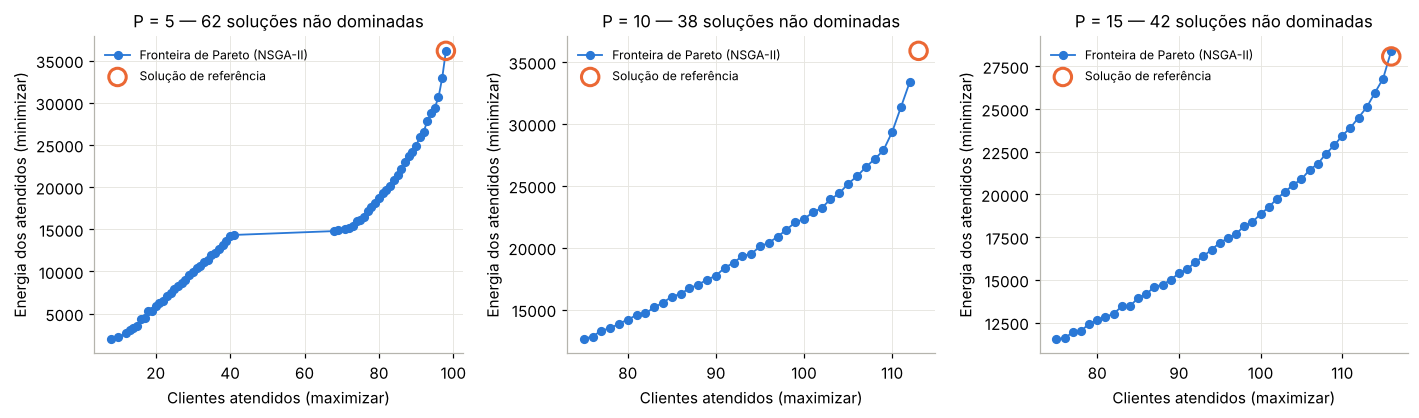

In [ ]:
creator.create("FitnessMulti", base.Fitness, weights=(-1.0, 1.0))
creator.create("IndividualMO", list, fitness=creator.FitnessMulti)

def avaliar_mo(ind):
    menor = Cp[:, ind].min(axis=1)
    atend = menor < PEN
    return float(menor[atend].sum()), int(atend.sum())

def executar_nsga2(P, pop=200, ngen=200, cxpb=0.9, mutpb=0.4, seed=None):
    random.seed(seed)
    populacao = [creator.IndividualMO(random.sample(range(N), P)) for _ in range(pop)]
    for ind in populacao:
        ind.fitness.values = avaliar_mo(ind)
    populacao = tools.selNSGA2(populacao, pop)                  # calcula a distância de multidão
    for _ in range(ngen):
        filhos = [creator.IndividualMO(ind) for ind in tools.selTournamentDCD(populacao, pop)]
        for f1, f2 in zip(filhos[::2], filhos[1::2]):
            if random.random() < cxpb:
                cx_conjunto(f1, f2)
        for f in filhos:
            if random.random() < mutpb:
                mut_troca(f, 1.0 / P)
            f.fitness.values = avaliar_mo(f)
        unicos = {}
        for ind in populacao + filhos:
            unicos.setdefault(frozenset(ind), ind)
        populacao = tools.selNSGA2(list(unicos.values()), pop)
    frente = tools.sortNondominated(populacao, len(populacao), first_front_only=True)[0]
    pts = sorted({ind.fitness.values for ind in frente}, key=lambda v: v[1])
    return np.array(pts)

P_MO = [5, 10, 15]
fig, axes = plt.subplots(1, len(P_MO), figsize=(13, 3.9))
for ax, P in zip(axes, P_MO):
    # une as fronteiras de 5 execuções e mantém só os pontos não dominados
    pts = np.vstack([executar_nsga2(P, seed=s) for s in range(5)])
    nd = np.array(sorted({tuple(p) for p in pts if not any((q[0] <= p[0] and q[1] >= p[1]) and tuple(q) != tuple(p) for q in pts)},
                         key=lambda v: v[1]))
    ax.plot(nd[:, 1], nd[:, 0], color=AZUL, marker="o", ms=5, lw=1.2, label="Fronteira de Pareto (NSGA-II)")
    e_ref, a_ref = OTIMO[P] - PEN * (M - REF[P][2]), REF[P][2]
    ax.scatter([a_ref], [e_ref], s=130, facecolor="none", edgecolor=LARANJA, linewidth=2, zorder=5,
               label="Solução de referência")
    na_frente = any(p[1] == a_ref and p[0] <= e_ref + 1e-6 for p in nd)
    ax.set(xlabel="Clientes atendidos (maximizar)", ylabel="Energia dos atendidos (minimizar)",
           title=f"P = {P} — {len(nd)} soluções não dominadas")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    print(f"P={P}: referência = ({e_ref:.0f}, {a_ref}) | NSGA-II atinge esse ponto: {na_frente} | "
          f"extremos: ({nd[0,0]:.0f}, {nd[0,1]:.0f}) a ({nd[-1,0]:.0f}, {nd[-1,1]:.0f})")
plt.tight_layout(); plt.show()

## 9. Conclusões

_(As frases abaixo foram escritas a partir das tabelas deste notebook; revise os números se reexecutar com outras sementes.)_

- **Modelagem.** Com B = 620 e penalidade de 10 000 por cliente não atendido, a função de avaliação reproduz exatamente os seis valores de referência da versão original; com U = 1,25·(demanda total)/P, reproduz também os seis da versão capacitada.
- **AG (algoritmo final).** Com a configuração escolhida no ajuste (população 200, mutação 0,4, cruzamento 0,9), o AG encontrou o valor ótimo em pelo menos uma das 20 execuções para todos os valores de P. O gap médio ficou abaixo de 0,06% em P = 5, 15, 20, 25 e 30. A instância mais difícil foi P = 10: gap médio de 0,65% e ótimo em apenas 1 das 20 execuções, porque existe um ótimo local muito atrativo (126283) e, em uma execução, a população ficou presa em uma solução que atende um cliente a menos (135317).
- **Algoritmo Memético.** A busca local de troca tornou o método mais confiável e mais rápido: 20 de 20 execuções ótimas em P = 15 e P = 20, e mais acertos também em P = 25 e 30, com menos da metade do tempo do AG. Em P = 10 ele melhorou a taxa de acerto (4 de 20), mas o gap médio (0,96%) não melhorou, pois os mesmos ótimos locais também são ótimos locais da vizinhança de troca.
- **Versão capacitada.** O AG com a heurística de atribuição ficou, em média, entre 0,06% e 1,7% do ótimo, com exceção de P = 15 (7,0%), em que a capacidade é muito justa e as soluções encontradas gastam bem mais energia que a ótima. Nenhuma execução atingiu exatamente o ótimo capacitado; com a atribuição exata sobre o melhor conjunto encontrado, P = 10 chega ao valor de referência (146632).
- **Multiobjetivo.** O NSGA-II gera, em uma única execução, todo o compromisso entre energia e atendimento. A solução de referência foi atingida em P = 5 e ficou próxima da fronteira encontrada em P = 10 e P = 15.

**Não implementado:** o extra (d), com número máximo K de drones, não foi feito neste notebook.

### Referências

- Fortin, F.-A. et al. *DEAP: Evolutionary Algorithms Made Easy*. Journal of Machine Learning Research, 13, 2012.
- Deb, K. et al. *A fast and elitist multiobjective genetic algorithm: NSGA-II*. IEEE Transactions on Evolutionary Computation, 6(2), 2002.
- Alp, O.; Erkut, E.; Drezner, Z. *An efficient genetic algorithm for the p-median problem*. Annals of Operations Research, 122, 2003.
- Moscato, P. *On evolution, search, optimization, genetic algorithms and martial arts: towards memetic algorithms*. Caltech Concurrent Computation Program, Report 826, 1989.